In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("..")

import jlinops

from solvers import GKSIAS

# Toy problem

In [2]:
ground_truth = jlinops.piecewise_constant_1d_test_problem()
n = len(ground_truth)
np.random.seed(0)
noise_stdev = 0.1
noise_var = noise_stdev**2
A = jlinops.Gaussian1DBlurOperator(n, blur_sigma=10, mode="reflect")
#A = jlinops.IdentityOperator((n,n))
noisy_signal = A.matvec(ground_truth) + noise_stdev*np.random.normal(size=n)
grid = np.arange(n)

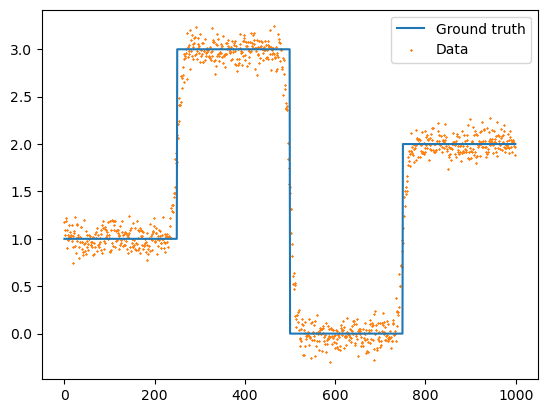

In [3]:
plt.plot(grid, ground_truth, label="Ground truth", color="C0")
plt.scatter(grid, noisy_signal, marker="x", label="Data", color="C1", alpha=1.0, s=0.5)
plt.legend()
plt.show()

# Define regularization

In [4]:
Lmat, Wmat = jlinops.first_order_derivative_1d(n, boundary="none")
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator

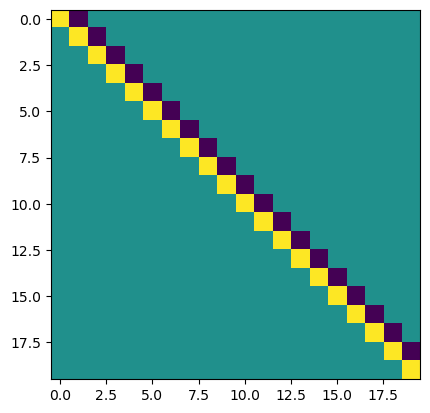

In [5]:
plt.imshow(Lmat.toarray()[:20,:20])
plt.show()

# Set up methods for comparison (first do convex case)

In [22]:
# TRIPs-Py methods are dp and gcv. The rest I have added. I believe dp is the same as dp3, except uses the GSVD in the formulation of the method whereas dp3 avoids using a GSVD.
#methods = ["dp", "dp2", "dp3", "mgcv", "gcv", "matlab_gcv", "mgcv_no_whitening", "gcv_no_whitening", "matlab_gcv_no_whitening" ]
#methods = ["gcv", "matlab_gcv", "dp", "dp3"]
# methods = ["dp", "dp3", "gcv", "mgcv", "matlab_gcv"]
methods = ["dp2", "matlab_gcv"]
print(f"Number of methods to compare: {len(methods)}")

Number of methods to compare: 2


In [23]:
# Set problem parameters
n_iters = 120
hyperpr_r = 1
hyperpr_beta = 1.5 + 1e-3

# hyperpr_r = -1
# hyperpr_beta = 1.0

# Build a dictionary containg solvers and solver results
comp_dct = {}

# Iterate over methods
for method in methods:
    print(f"Started method: {method}")

    # Build solver
    if (method == "mgcv_no_whitening") or (method == "gcv_no_whitening") or (method == "matlab_gcv_no_whitening"):
        gksias_solver = GKSIAS(A, L, noisy_signal, noise_var=None)
    else:
        gksias_solver = GKSIAS(A, L, noisy_signal, noise_var=noise_var)

    # Processing for regparam method
    if (method == "mgcv_no_whitening"):
        regparam = "mgcv"
    elif (method == "gcv_no_whitening"):
        regparam = "gcv"
    elif (method == "matlab_gcv_no_whitening"):
        regparam = "matlab_gcv"
    else:
        regparam = method


    # Run the solver
    data = gksias_solver.solve(n_iter=n_iters, init_dim=5, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, x_true=ground_truth, regparam=regparam, regparam_fixed=1e0)

    # Put results into dict
    comp_dct[method] = data

Started method: dp2


Started method: matlab_gcv


# Comparison plots

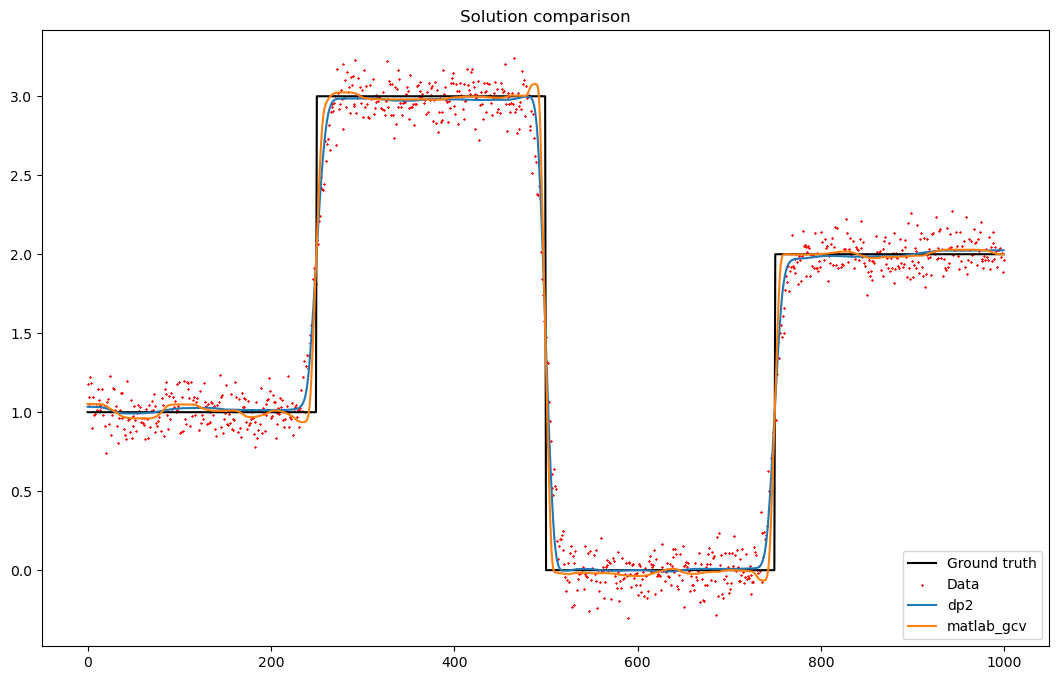

In [24]:
plt.figure(figsize=(13,8))

plt.plot(grid, ground_truth, label="Ground truth", color="black")
plt.scatter(grid, noisy_signal, marker="x", label="Data", color="red", alpha=1.0, s=0.5)

for method in comp_dct.keys():
    data = comp_dct[method]
    plt.plot(grid, data["x"], label=method)

plt.legend(loc="lower right")
plt.title("Solution comparison")
plt.show()

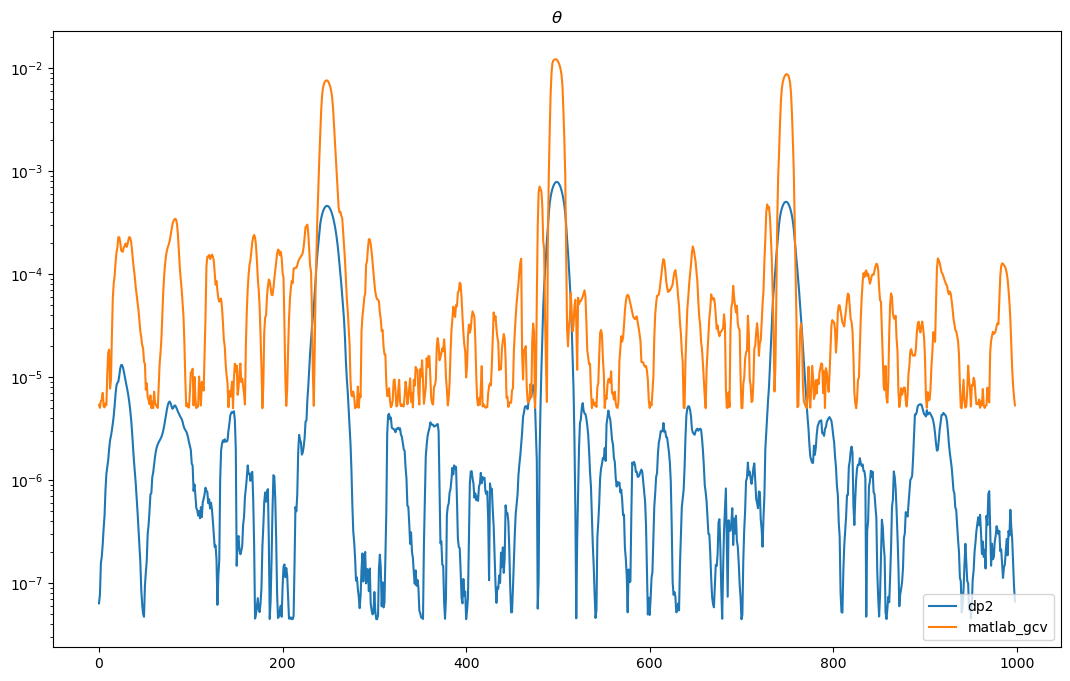

In [25]:
plt.figure(figsize=(13,8))


for method in comp_dct.keys():
    data = comp_dct[method]
    plt.semilogy(grid[:-1], data["theta"], label=method)

plt.legend(loc="lower right")
plt.title("$\\theta$")
plt.show()

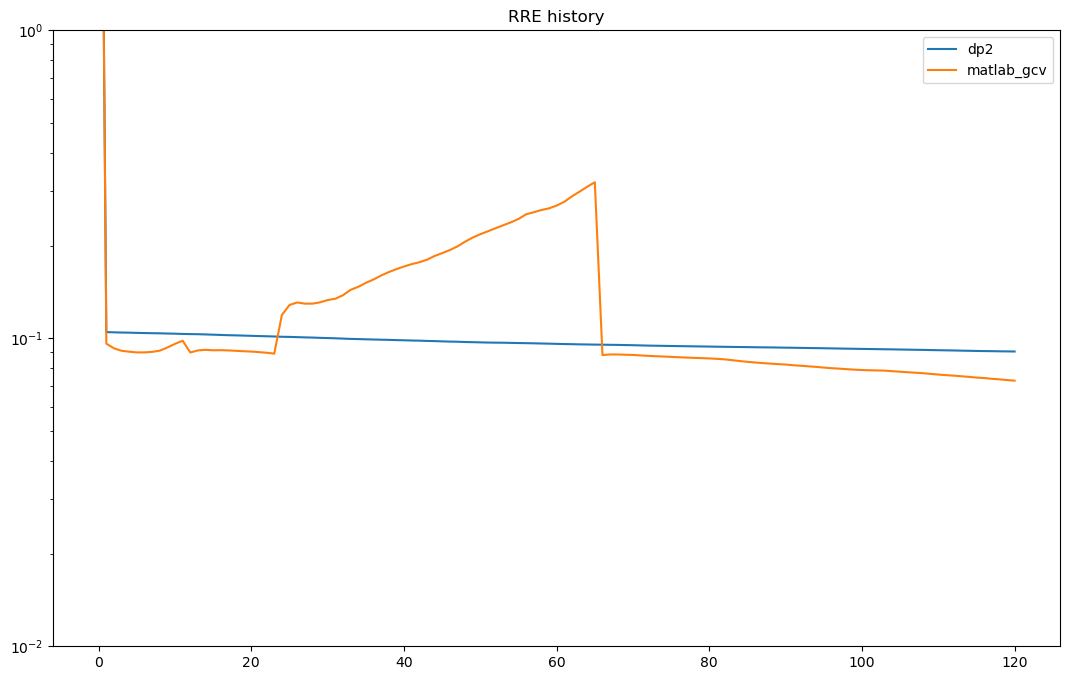

In [26]:
plt.figure(figsize=(13,8))


for method in comp_dct.keys():
    data = comp_dct[method]
    plt.semilogy(data["rre_history"], label=method)

plt.legend(loc="upper right")
plt.title("RRE history")
plt.ylim(1e-2, 1e-0)
plt.show()

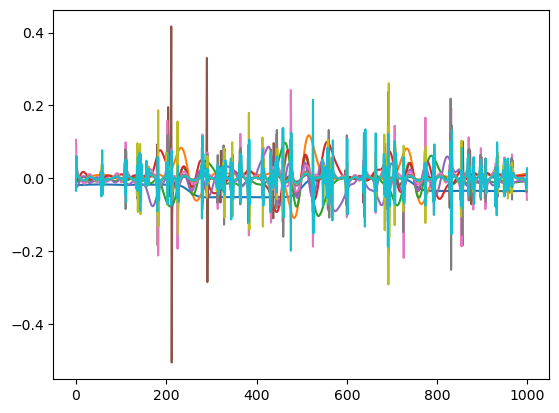

In [27]:
for j in range(10):
    plt.plot( comp_dct["dp2"]["V"][:,j] )
plt.show()

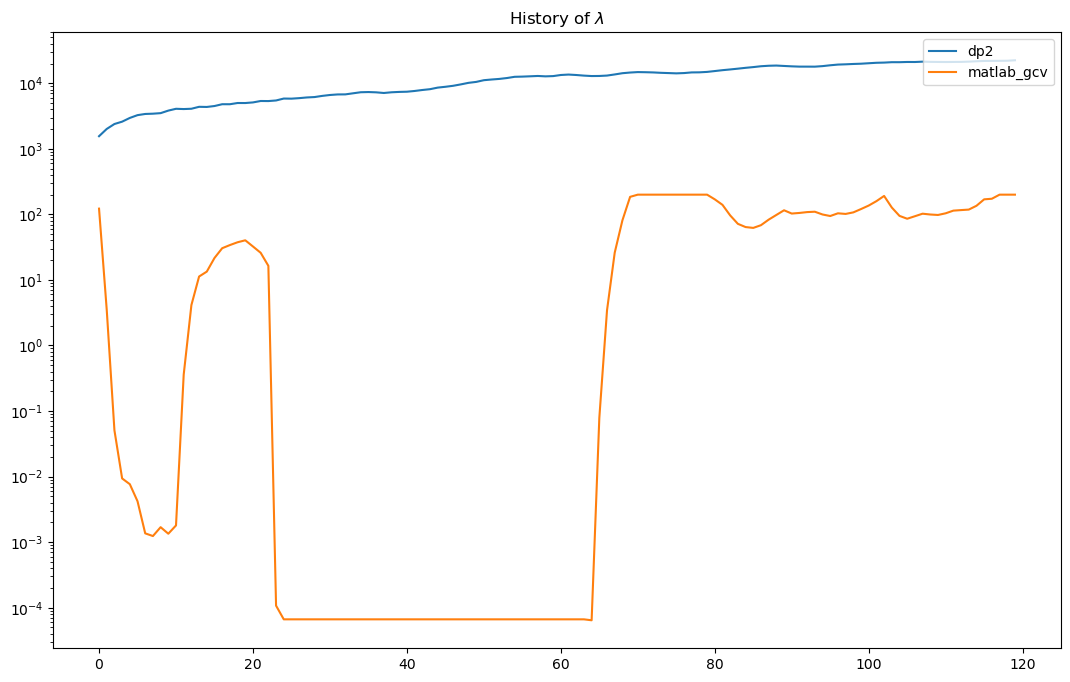

In [28]:
plt.figure(figsize=(13,8))

for method in comp_dct.keys():
    data = comp_dct[method]
    plt.semilogy(data["lambda_history"], label=method)

plt.legend(loc="upper right")
plt.title("History of $\\lambda$")
plt.show()

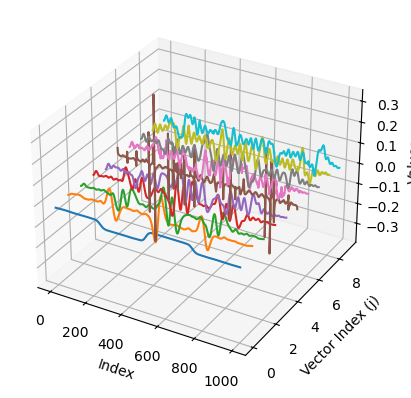

In [29]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

# Define K (number of column vectors to plot)
K = 10  # For example, plot the first 10 column vectors

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Assuming data[1]["V"] is a 2D array
X = np.arange(data["V"].shape[0])  # X-axis: indices of the vectors
Y = np.arange(min(K, data["V"].shape[1]))  # Y-axis: the varying index (j), limited by K

# Loop through the first K vectors and plot them
for j in range(K):
    ax.plot(X, np.full(X.shape, Y[j]), data["V"][:, j])

# Labels (optional)
ax.set_xlabel('Index')
ax.set_ylabel('Vector Index (j)')
ax.set_zlabel('Values')

plt.show()


# Also do a nonconvex prior?

In [9]:
# Set problem parameters
n_iters = 120
hyperpr_r = -1
hyperpr_beta = 1.0

# Build a dictionary containg solvers and solver results
comp_dct = {}

# Iterate over methods
for method in methods:
    print(f"Started method: {method}")

    # Build solver
    if (method == "mgcv_no_whitening") or (method == "gcv_no_whitening") or (method == "matlab_gcv_no_whitening"):
        gksias_solver = GKSIAS(A, L, noisy_signal, noise_var=None)
    else:
        gksias_solver = GKSIAS(A, L, noisy_signal, noise_var=noise_var)

    # Processing for regparam method
    if (method == "mgcv_no_whitening"):
        regparam = "mgcv"
    elif (method == "gcv_no_whitening"):
        regparam = "gcv"
    elif (method == "matlab_gcv_no_whitening"):
        regparam = "matlab_gcv"
    else:
        regparam = method

    try:
        # Run the solver
        data = gksias_solver.solve(n_iter=n_iters, init_dim=10, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, x_true=ground_truth, regparam=regparam, regparam_fixed=1e0)
    except:
        print(f"failed for method = {method}")

    # Put results into dict
    comp_dct[method] = data

Started method: dp2


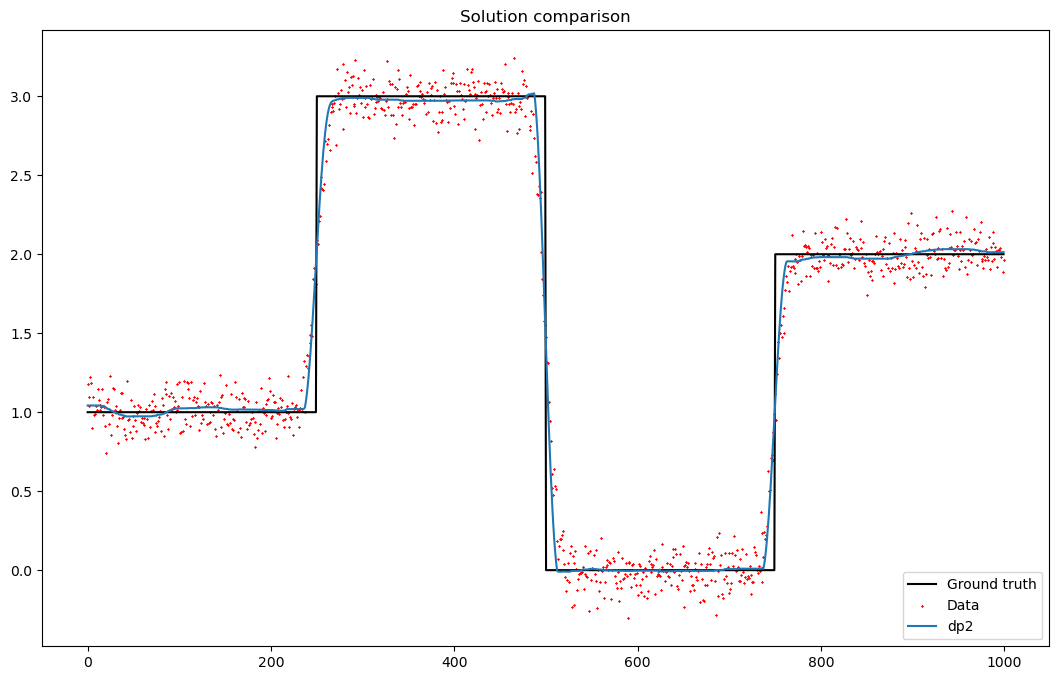

In [10]:
plt.figure(figsize=(13,8))

plt.plot(grid, ground_truth, label="Ground truth", color="black")
plt.scatter(grid, noisy_signal, marker="x", label="Data", color="red", alpha=1.0, s=0.5)

for method in comp_dct.keys():
    if method == "dp":
        pass
    else:
        data = comp_dct[method]
        plt.plot(grid, data["x"], label=method)

plt.legend(loc="lower right")
plt.title("Solution comparison")
plt.show()

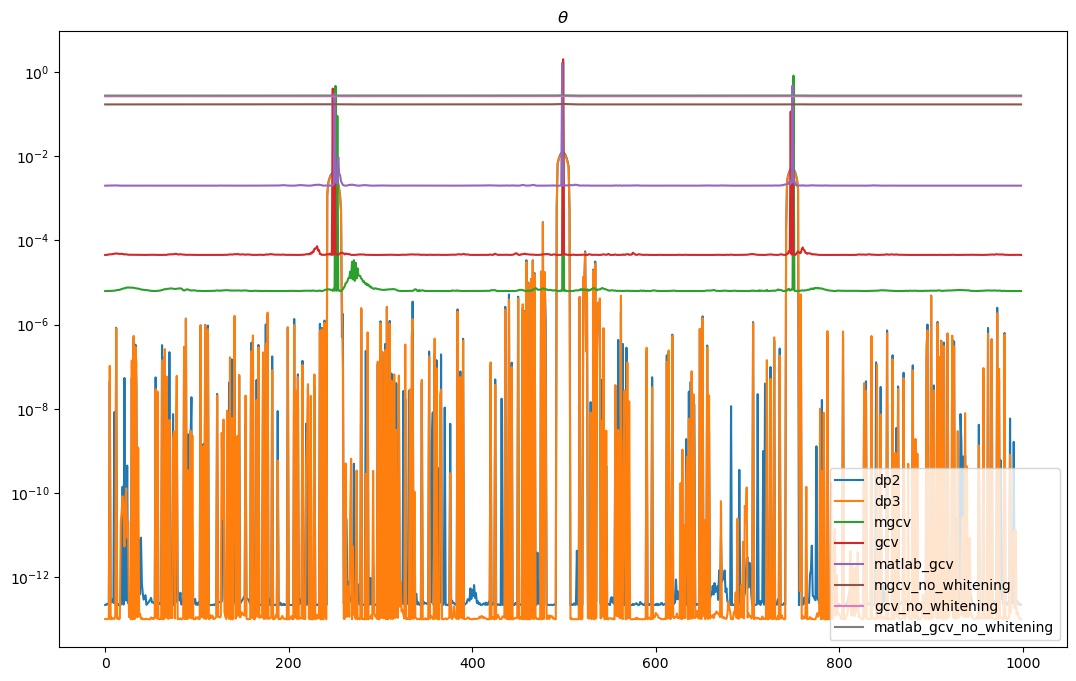

In [ ]:
plt.figure(figsize=(13,8))


for method in comp_dct.keys():
    if method == "dp":
        pass
    else:
        data = comp_dct[method]
        plt.semilogy(grid[:-1], data["theta"], label=method)

plt.legend(loc="lower right")
plt.title("$\\theta$")
plt.show()

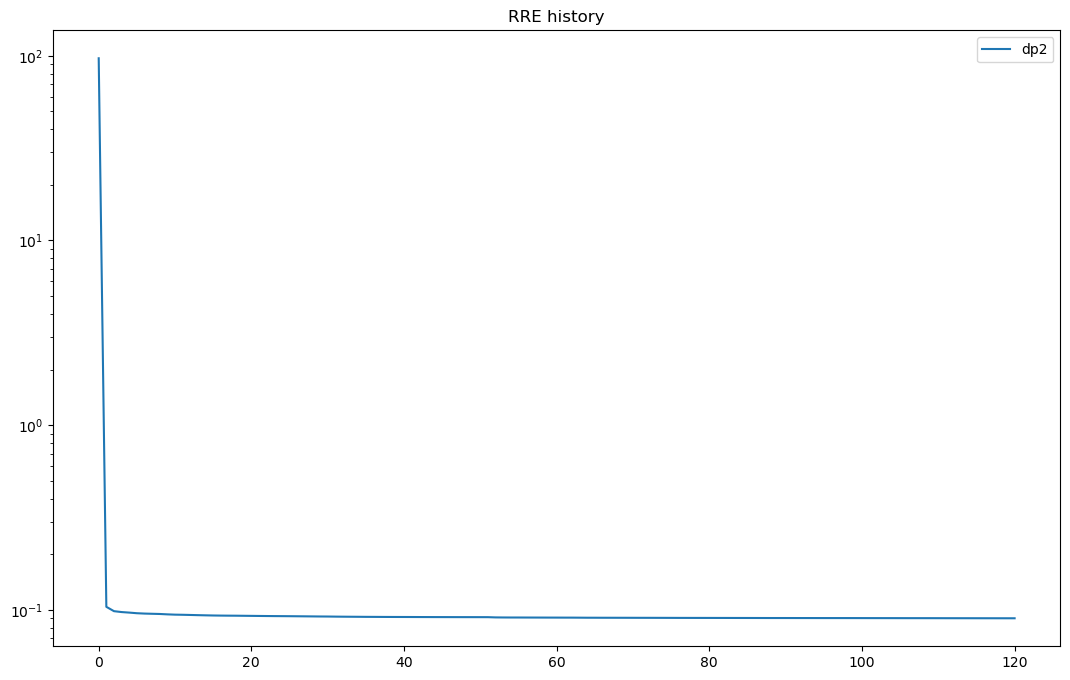

In [11]:
plt.figure(figsize=(13,8))


for method in comp_dct.keys():
    if method == "dp":
        pass
    else:
        data = comp_dct[method]
        plt.semilogy(data["rre_history"], label=method)

plt.legend(loc="upper right")
plt.title("RRE history")
plt.show()

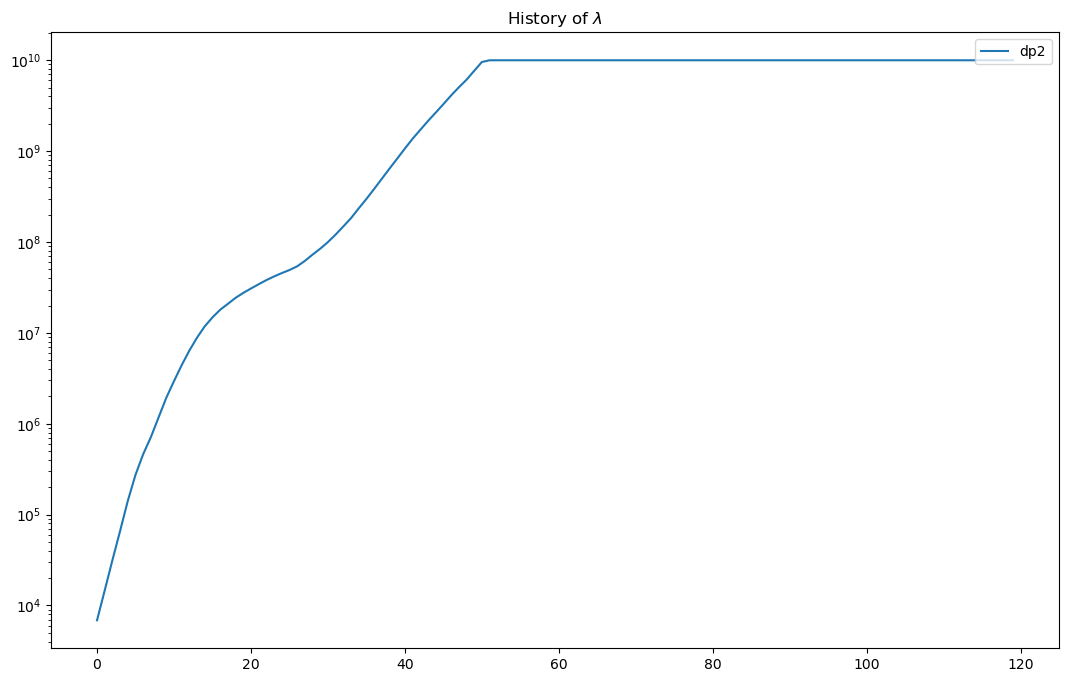

In [12]:
plt.figure(figsize=(13,8))

for method in comp_dct.keys():
    if method == "dp":
        pass
    else:
        data = comp_dct[method]
        plt.semilogy(data["lambda_history"], label=method)

plt.legend(loc="upper right")
plt.title("History of $\\lambda$")
plt.show()

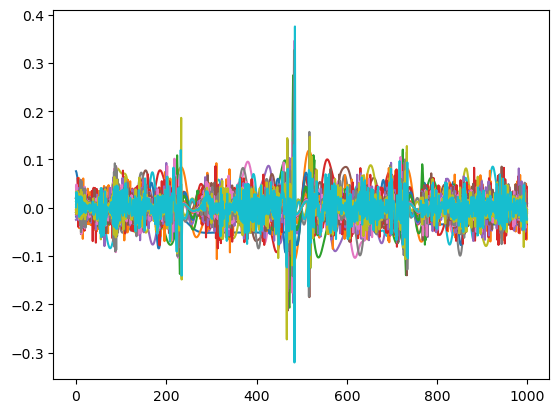

In [14]:
for j in range(20):
    plt.plot(data["V"][:,j] )
plt.show()